# Import libs and load data

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import Normalizer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

data_refined = pd.read_csv('data\\df_refined.csv', index_col=0)

In [2]:
data_refined

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,label
0,-0.054405,0.017853,-0.041799,-0.054094,0.234341,0.244889,0.137710,0.104796,0.205176,0.350901,...,0.009316,-0.017252,-0.038741,0.241800,0.279060,0.142368,0.156688,0.433463,0.352140,1
1,0.298471,-0.195691,0.302899,0.311343,0.047969,0.093131,0.234316,0.244862,-0.000675,-0.095090,...,-0.248392,0.229276,0.209324,0.037712,-0.052272,0.104761,0.125759,-0.146556,-0.066494,1
2,-0.081586,-0.145786,-0.066032,-0.086702,0.389171,0.218908,0.152368,0.145708,0.175891,0.329183,...,-0.054954,-0.018476,-0.041007,0.355689,0.301177,0.220528,0.159889,0.307162,0.390104,1
3,0.295252,0.039278,0.287013,0.276289,-0.030014,0.023925,0.077047,0.164854,-0.014696,-0.190308,...,0.079731,0.345749,0.322516,0.129970,0.006767,0.128652,0.302959,0.067471,-0.002611,1
4,-0.026309,0.084289,-0.015437,-0.050235,0.381393,0.274170,0.016228,0.069485,0.334910,0.395153,...,0.094275,0.025903,0.009138,0.343677,0.174030,-0.003819,0.151222,0.115398,0.410691,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
561,0.252605,0.085407,0.246592,0.280351,0.124218,0.027048,0.233363,0.278715,-0.036558,-0.110675,...,0.013601,0.210476,0.241949,0.045214,-0.031927,0.079679,0.195904,-0.161649,-0.083784,1
562,0.269213,0.326476,0.255210,0.272181,0.016527,-0.001742,0.110219,0.200724,-0.033297,-0.165954,...,0.319868,0.225425,0.237019,-0.107766,-0.061210,0.037903,0.117161,-0.082718,-0.151981,1
563,0.183712,0.527062,0.176039,0.151527,-0.216045,-0.008283,0.013898,0.029801,-0.207609,-0.230979,...,0.353221,0.152466,0.113395,-0.207827,0.092309,0.085667,0.109860,-0.284510,-0.081023,1
564,0.166085,0.209409,0.179036,0.156799,0.137147,0.296299,0.297701,0.240814,0.192538,0.093953,...,0.200130,0.208500,0.149918,0.128343,0.352140,0.287613,0.207445,0.173506,0.199486,1


In [3]:
insurance = pd.read_csv('data\\insurance.csv')
insurance.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [4]:
insurance.shape
insurance.charges

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

# Pre-processing

In [5]:
target_insurance = insurance.charges

In [6]:
target_insurance

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

In [7]:
num_insurance = insurance.select_dtypes(exclude='object')
insurance.drop(num_insurance.columns, axis=1, inplace=True)
insurance

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest
...,...,...,...
1333,male,no,northwest
1334,female,no,northeast
1335,female,no,southeast
1336,female,no,southwest


In [8]:
scale = StandardScaler()
scaled_num_insurance = scale.fit_transform(num_insurance)
scaled_num_insurance

array([[-1.43876426, -0.45332   , -0.90861367,  0.2985838 ],
       [-1.50996545,  0.5096211 , -0.07876719, -0.95368917],
       [-0.79795355,  0.38330685,  1.58092576, -0.72867467],
       ...,
       [-1.50996545,  1.0148781 , -0.90861367, -0.96159623],
       [-1.29636188, -0.79781341, -0.90861367, -0.93036151],
       [ 1.55168573, -0.26138796, -0.90861367,  1.31105347]])

In [9]:
scaled_insurance_df = pd.DataFrame(scaled_num_insurance)
scaled_insurance_df.columns = num_insurance.columns
scaled_insurance_df

,age,bmi,children,charges
0,-1.438764,-0.453320,-0.908614,0.298584
1,-1.509965,0.509621,-0.078767,-0.953689
2,-0.797954,0.383307,1.580926,-0.728675
3,-0.441948,-1.305531,-0.908614,0.719843
4,-0.513149,-0.292556,-0.908614,-0.776802
...,...,...,...,...
1333,0.768473,0.050297,1.580926,-0.220551
1334,-1.509965,0.206139,-0.908614,-0.914002
1335,-1.509965,1.014878,-0.908614,-0.961596
1336,-1.296362,-0.797813,-0.908614,-0.930362


In [10]:
insurance.sex = insurance.sex.apply(lambda x:1 if x=='female' else 0)

In [11]:
insurance.smoker = insurance.smoker.apply(lambda x:1 if x=='yes' else 0)

In [12]:
insurance

,sex,smoker,region
0,1,1,southwest
1,0,0,southeast
2,0,0,southeast
3,0,0,northwest
4,0,0,northwest
...,...,...,...
1333,0,0,northwest
1334,1,0,northeast
1335,1,0,southeast
1336,1,0,southwest


In [13]:
insurance = pd.get_dummies(insurance)
insurance = pd.concat([insurance, scaled_insurance_df], axis=1, ignore_index=True)

In [14]:
insurance.to_csv('data\\insurance_refined.csv')

In [15]:
insurance

,0,1,2,3,4,5,6,7,8,9
0,1,1,False,False,False,True,-1.438764,-0.453320,-0.908614,0.298584
1,0,0,False,False,True,False,-1.509965,0.509621,-0.078767,-0.953689
2,0,0,False,False,True,False,-0.797954,0.383307,1.580926,-0.728675
3,0,0,False,True,False,False,-0.441948,-1.305531,-0.908614,0.719843
4,0,0,False,True,False,False,-0.513149,-0.292556,-0.908614,-0.776802
...,...,...,...,...,...,...,...,...,...,...
1333,0,0,False,True,False,False,0.768473,0.050297,1.580926,-0.220551
1334,1,0,True,False,False,False,-1.509965,0.206139,-0.908614,-0.914002
1335,1,0,False,False,True,False,-1.509965,1.014878,-0.908614,-0.961596
1336,1,0,False,False,False,True,-1.296362,-0.797813,-0.908614,-0.930362


# Clustering: Kmeans

c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

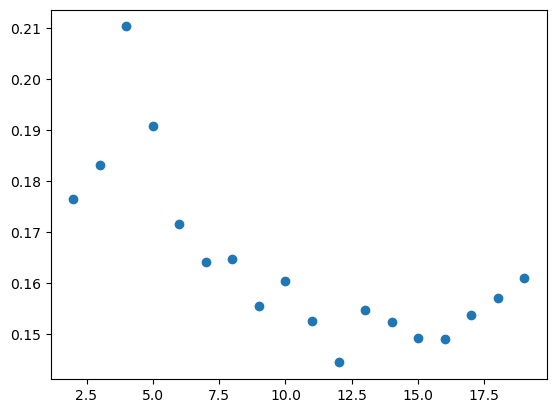

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


score_lst = []
for k in range(2,20):
    model = KMeans(n_clusters=k)
    model.fit(insurance)
    score_lst.append(silhouette_score(insurance, model.predict(insurance)))



plt.scatter(range(2,20), score_lst)

In [17]:
print('The optimal k in the KMeans method for insurance is: ', np.argmax(score_lst)+2)

The optimal k in the KMeans method for insurance is:  4


c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ali_m\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

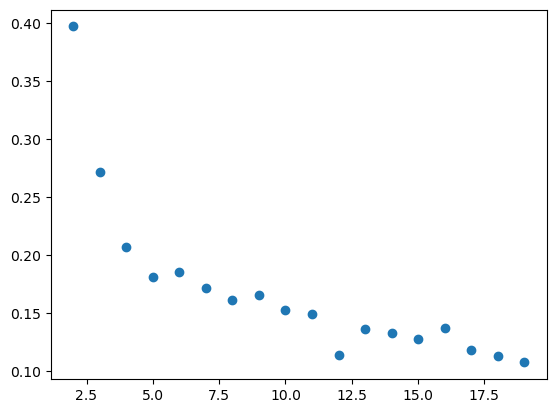

In [18]:
score_lst = []
for k in range(2,20):
    model = KMeans(n_clusters=k)
    model.fit(data_refined)
    score_lst.append(silhouette_score(data_refined, model.predict(data_refined)))



plt.scatter(range(2,20), score_lst)

In [19]:
print('The optimal k in the KMeans method for the breast cancer is: ', np.argmax(score_lst)+2)

The optimal k in the KMeans method for the breast cancer is:  2


# Clustering: Mean-shift

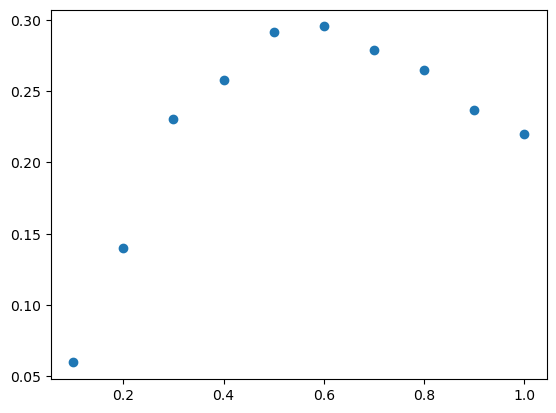

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import MeanShift


score_lst = []
for k in np.linspace(0.1, 1, 10):
    model = MeanShift(bandwidth=k)
    model.fit(insurance)
    score_lst.append(silhouette_score(insurance, model.predict(insurance)))



plt.scatter(np.linspace(0.1, 1, 10), score_lst)

In [21]:
lst = np.linspace(0.1, 1, 10)
print('The optimal bandwidth in the Mean-shift method for the insurance is: ', lst[np.argmax(score_lst)])

The optimal bandwidth in the Mean-shift method for the insurance is:  0.6


0.5
0.625
0.75
0.875
1.0


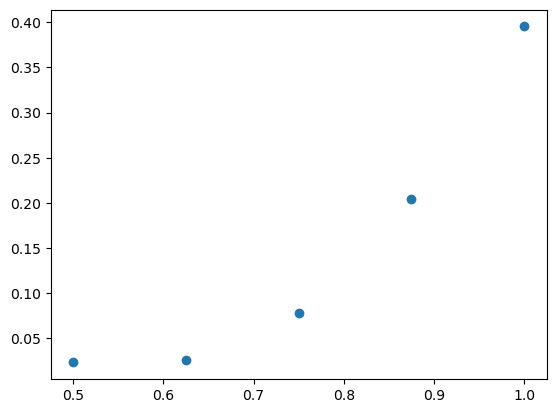

In [22]:
score_lst = []
for k in np.linspace(0.5, 1, 5):
    model = MeanShift(bandwidth=k)
    model.fit(data_refined)
    score_lst.append(silhouette_score(data_refined, model.predict(data_refined)))
    print(k)



plt.scatter(np.linspace(0.5, 1, 5), score_lst)

In [23]:
lst = np.linspace(0.5, 1, 5)
print('The optimal bandwidth in the Mean-shift method for the breast cancer is: ', lst[np.argmax(score_lst)])

The optimal bandwidth in the Mean-shift method for the breast cancer is:  1.0


# Clustering: DBSCAN

In [24]:
from sklearn.cluster import DBSCAN

model = DBSCAN(eps=1.5)
model.fit(insurance)
silhouette_score(insurance, model.labels_)

0.3036828101562804

In [25]:
model = DBSCAN(eps=1)
model.fit(data_refined)
silhouette_score(data_refined, model.labels_)

0.268065476605118

# ANN

In [ ]:
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

In [32]:
from sklearn.model_selection import train_test_split


X = insurance.iloc[:,:-1]
y = target_insurance
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

In [34]:
X_train.shape

(1070, 9)

In [ ]:
type((X_train.shape[1],))

int

In [57]:

from tensorflow.keras.callbacks import EarlyStopping


model = Sequential()
model.add(Dense(32, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))


model.compile(optimizer='adam', loss='mse', metrics=['mae'])


es_cb = EarlyStopping(monitor='loss', patience=5)
model.fit(X_train, y_train, epochs=100, callbacks=es_cb, validation_data=(X_val, y_val))

Epoch 1/100


c:\Users\ali_m\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 299096544.0000 - mae: 12847.0967 - val_loss: 349324288.0000 - val_mae: 13490.3857
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 310876672.0000 - mae: 13025.1133 - val_loss: 347760288.0000 - val_mae: 13438.4209
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 318640544.0000 - mae: 13349.9502 - val_loss: 333731232.0000 - val_mae: 12970.9414
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 300322176.0000 - mae: 12443.5352 - val_loss: 266805888.0000 - val_mae: 10755.9131
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 205890944.0000 - mae: 9474.3574 - val_loss: 137501936.0000 - val_mae: 7667.6772
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 118872816.0000 - mae: 7644.1875 - val_loss: 101826208.0000 - val_mae: 8298.2959
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 105528872.0000 - mae: 8343.4668 - val_loss: 93187664.0000 - val_mae: 7658.9937
Epoch 8/100
34/34 ━━━━━━━━━━━━━━

In [58]:
from tensorflow.keras.metrics import RootMeanSquaredError

rmse = RootMeanSquaredError()

y_pred = model.predict(X_test)

rmse(y_pred, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


<tf.Tensor: shape=(), dtype=float32, numpy=4348.3203125>